# Experiment 5 analysis

The basics: loading `results/timings.csv`, turning batch totals into per-operation costs,
summarizing replicates, and estimating a growth rate from a log-log fit (how fast the cost grows as the data grows).
It uses the rows from the worked `example` experiment (`make experiments ... ONLY=example`).

In [22]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RESULTS = Path("..") / "results" / "timings.csv"
df = pd.read_csv(RESULTS)

# Per-operation cost: every row is a batch of n_ops operations.
df["us_per_op"] = df["total_ns"] / df["n_ops"] / 1_000 # The microseconds one operation took
for counter in ["comparisons", "nodes_visited", "rotations", "splits", "resizes"]:
    df[f"{counter}_per_op"] = df[counter] / df["n_ops"]

df[["experiment", "code_version", "machine_id", "index_type", "operation", "n_keys", "rep", "us_per_op", "rotations_per_op"]].head()

,experiment,code_version,machine_id,index_type,operation,n_keys,rep,us_per_op,rotations_per_op
0,CORE,7e96499,saariya-mbp,unsorted_list,build,10000,0,0.122900,0.0
1,CORE,7e96499,saariya-mbp,unsorted_list,build,114000,0,0.111384,0.0
2,CORE,7e96499,saariya-mbp,unsorted_list,point_hit,114000,0,3924.546877,0.0
3,CORE,7e96499,saariya-mbp,unsorted_list,point_miss,114000,0,3811.619044,0.0
4,CORE,7e96499,saariya-mbp,unsorted_list,range,114000,0,3680.383540,0.0


## Always know which code you're looking at

Rows from before and after a bug fix live in the same file. Filter on `code_version`
(and `machine_id`) before you compare anything.

In [8]:
df.groupby(["code_version", "machine_id", "experiment"]).size()

code_version  machine_id   experiment     
7e96499       saariya-mbp  CORE               210
9e83b18       saariya-mbp  E5_insert_order    840
dtype: int64

In [12]:
# ---- CONFIG: the only place to change ----
VERSION = None   # None = newest code_version in the file, or set a hash like "7e96499"
MACHINE = None   # None = machine with the newest E5 rows, or set e.g. "saariya-mbp"
# ------------------------------------------

e5_all = df[df["experiment"] == "E5_insert_order"]
newest = e5_all.sort_values("timestamp_utc").iloc[-1] # picks the most recent experiment based on timestamp
version = VERSION or newest["code_version"] # used the most recent version of experiment 5 unless specified
machine = MACHINE or newest["machine_id"]

e5 = e5_all[(e5_all["code_version"] == version) & (e5_all["machine_id"] == machine)] # filters df e5_all further only by the specified machine and version
assert len(e5) > 0, f"no E5 rows for version={version}, machine={machine}" #stops running the function if there are no rows for specified version/machines e5
print(f"Analyzing code_version={version}  machine_id={machine}  rows={len(e5)}")
if e5_all["code_version"].nunique() > 1:
    print("NOTE: the file has E5 rows from several code versions:",
          sorted(e5_all["code_version"].unique())) # Flags if multiple versions of of e5 being considered

# Summary across replicates
summary = (
    e5.groupby(["operation", "index_type", "insert_order", "n_keys"])["us_per_op"]
    .describe(percentiles=[0.25, 0.5, 0.75])[["count", "25%", "50%", "75%"]] # time taken per operation for each of the 5 reps consolidated as 25 percentile, median, 75 percentile
    .rename(columns={"50%": "median"})
)
summary

Analyzing code_version=9e83b18  machine_id=saariya-mbp  rows=840


count          25%       median  \
operation index_type    insert_order  n_keys                                    
build     avl_tree      nearly_sorted 1000      5.0     7.698042     7.726125   
                                      10000     5.0    10.370975    10.507683   
                                      100000    5.0    13.362406    13.431583   
                        random        1000      5.0     8.500167     8.519875   
                                      10000     5.0    13.219633    13.350925   
...                                             ...          ...          ...   
point_hit unsorted_list reversed      10000     5.0   285.511667   309.357583   
                                      100000    5.0  3328.460252  3362.782460   
                        sorted        1000      5.0    28.203126    28.689500   
                                      10000     5.0   247.520958   248.379084   
                                      100000    5.0  3606.893127  3621.517043   

                                                      75%  
operation index_type    insert_order  n_keys               
build     avl_tree      nearly_sorted 1000       7.820375  
                                      10000     10.518800  
                                      100000    13.586225  
                        random        1000       8.697334  
                                      10000     14.763838  
...                                                   ...  
point_hit unsorted_list reversed      10000    335.248875  
                                      100000  3377.073169  
                        sorted        1000      29.559334  
                                      10000    265.539125  
                                      100000  3930.451668  

[168 rows x 4 columns]

## Build Cost vs. n on log-log axes

On log-log axes, cost proportional to $n^k$ is a straight line with slope $k$:
roughly 0 for constant time, 1 for linear time, and slowly bending for $\log n$.         Lines are medians; bands are the IQR.

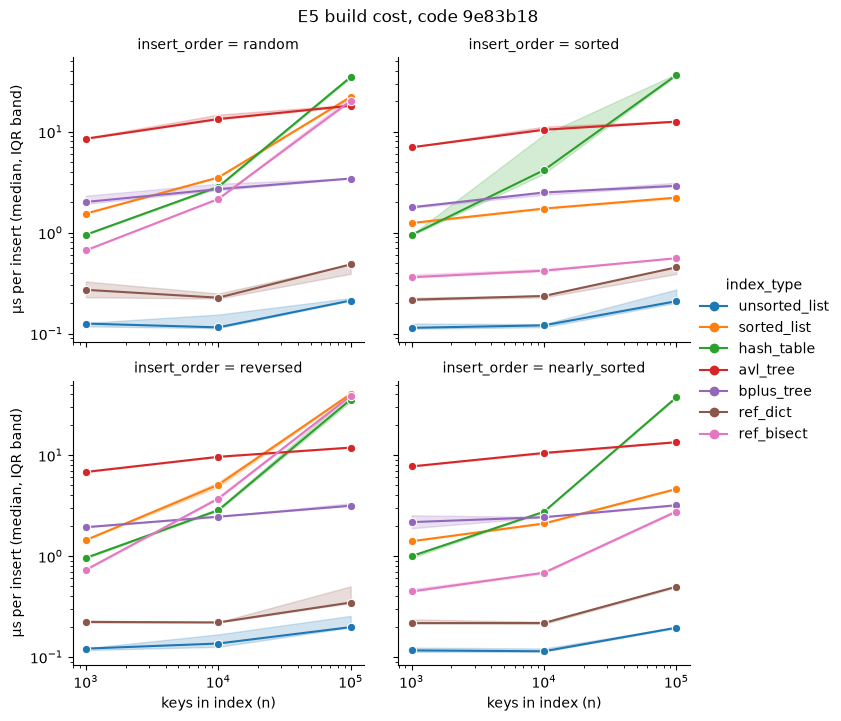

In [13]:
# checking build cost against order of keys 
build = e5[e5["operation"] == "build"] 
g = sns.relplot(
    data=build, x="n_keys", y="us_per_op", hue="index_type",
    col="insert_order", col_wrap=2, kind="line",
    estimator="median", errorbar=("pi", 50), marker="o", height=3.5,
)
g.set(xscale="log", yscale="log")
g.set_axis_labels("keys in index (n)", "µs per insert (median, IQR band)")
g.figure.suptitle(f"E5 build cost, code {version}", y=1.02)
plt.show()

## Point-lookup cost vs. n, one panel per arrival order

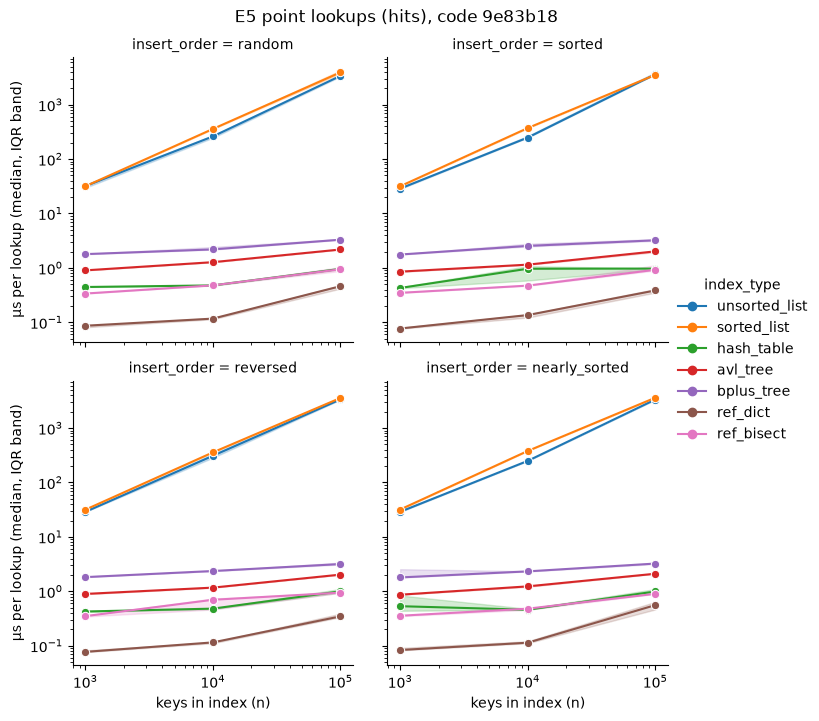

In [15]:
# checking point look up cost against order of keys 

hits = e5[e5["operation"] == "point_hit"]
g = sns.relplot(
    data=hits, x="n_keys", y="us_per_op", hue="index_type",
    col="insert_order", col_wrap=2, kind="line",
    estimator="median", errorbar=("pi", 50), marker="o", height=3.5,
)
g.set(xscale="log", yscale="log")
g.set_axis_labels("keys in index (n)", "µs per lookup (median, IQR band)")
g.figure.suptitle(f"E5 point lookups (hits), code {version}", y=1.02)
plt.show()

## Estimating the growth exponent

Fit $\log_{10}(\text{cost}) = a + k \log_{10}(n)$ to the per-n medians. With only three sizes
this is a rough estimate; your experiments should use more sizes, and you should report an
interval for $k$ (e.g. bootstrap over replicates), not just a point estimate.

In [23]:
# Point estimate
rows = []
for (idx, order, op), g in e5.groupby(["index_type", "insert_order", "operation"]): #df e5 is grouped by the following categories - especially, key arrival order by index & operation type
    med = g.groupby("n_keys")["us_per_op"].median() # for all 3 n_keys (1000, 10000,1000000 - itg picks the median timing of the 5 reps - we will have 3 median timings)
    k, a = np.polyfit(np.log10(med.index.to_numpy(dtype=float)), np.log10(med.values), 1) # fits the median data into the given function... index gives x-values and med.values picks the 3 median values (one median per size), y = k·x + a... if k=0, slope is a horizontal line o degree 1
    rows.append({"index_type": idx, "insert_order": order, "operation": op, "slope_k": round(k, 2)})

slopes = pd.DataFrame(rows).pivot_table(
    index=["operation", "index_type"], columns="insert_order", values="slope_k"
)
slopes

insert_order             nearly_sorted  random  reversed  sorted
operation index_type                                            
build     avl_tree                0.12    0.16      0.12    0.13
          bplus_tree              0.08    0.12      0.11    0.11
          hash_table              0.79    0.78      0.78    0.79
          ref_bisect              0.40    0.74      0.86    0.09
          ref_dict                0.18    0.13      0.10    0.16
          sorted_list             0.26    0.58      0.72    0.13
          unsorted_list           0.11    0.11      0.11    0.13
point_hit avl_tree                0.19    0.19      0.18    0.19
          bplus_tree              0.13    0.13      0.12    0.13
          hash_table              0.14    0.17      0.19    0.18
          ref_bisect              0.20    0.22      0.22    0.21
          ref_dict                0.41    0.36      0.33    0.35
          sorted_list             1.03    1.05      1.03    1.02
          unsorted_list           1.03    1.01      1.03    1.05

In [24]:
def bootstrap_slope(g, n_boot=1000, seed=0):
    rng = np.random.default_rng(seed)
    sizes = sorted(g["n_keys"].unique())  # the 3 sizes
    by_n = {n: g[g["n_keys"] == n]["us_per_op"].to_numpy() for n in sizes}  # the 5 reps at each size
    slopes_boot = []
    for _ in range(n_boot):
        # redraw 5 reps per size with replacement, take the median per size, refit the slope
        meds = [np.median(rng.choice(by_n[n], size=len(by_n[n]), replace=True)) for n in sizes] #1000 medians per size returned
        slopes_boot.append(np.polyfit(np.log10(sizes), np.log10(meds), 1)[0])
    return np.percentile(slopes_boot, [2.5, 97.5])  # middle 95% of the 1,000 slopes

rows_ci = []
for (idx, order, op), g in e5.groupby(["index_type", "insert_order", "operation"]):
    lo, hi = bootstrap_slope(g)
    rows_ci.append({"index_type": idx, "insert_order": order, "operation": op,
                    "k_low": round(lo, 2), "k_high": round(hi, 2)})

slopes_ci = pd.DataFrame(rows_ci)
slopes_ci

,index_type,insert_order,operation,k_low,k_high
0,avl_tree,nearly_sorted,build,0.12,0.13
1,avl_tree,nearly_sorted,point_hit,0.19,0.21
2,avl_tree,random,build,0.16,0.19
3,avl_tree,random,point_hit,0.19,0.20
4,avl_tree,reversed,build,0.12,0.12
5,avl_tree,reversed,point_hit,0.17,0.19
6,avl_tree,sorted,build,0.11,0.16
7,avl_tree,sorted,point_hit,0.17,0.21
8,bplus_tree,nearly_sorted,build,0.01,0.12
9,bplus_tree,nearly_sorted,point_hit,0.00,0.14


## Counters vs. timings

Counters (`comparisons_per_op`, `nodes_visited_per_op`, ...) are deterministic, so they have no
replicate-to-replicate noise and are identical on every machine. Plot them against theory,
e.g. $\log_2 n$ for a balanced binary tree. The reference indexes (`ref_*`) don't count operations.

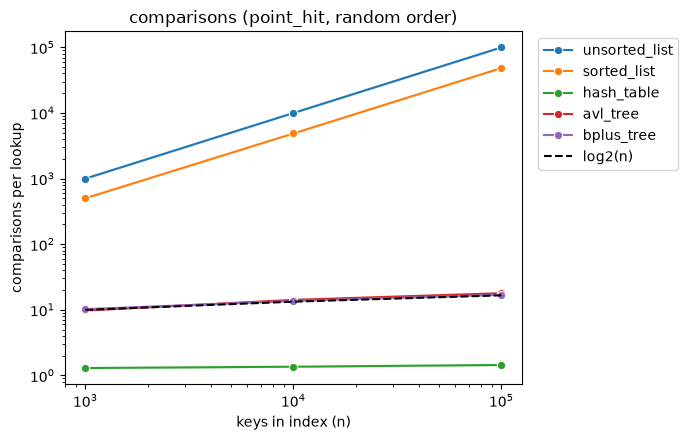

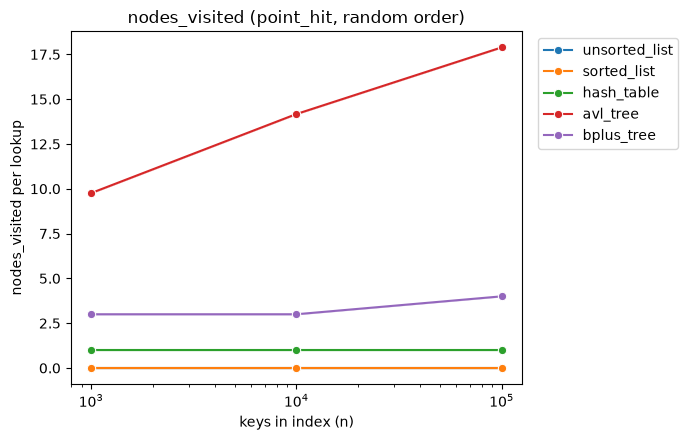

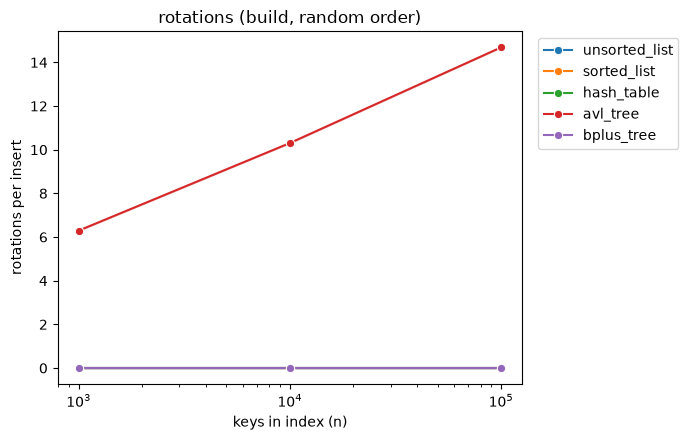

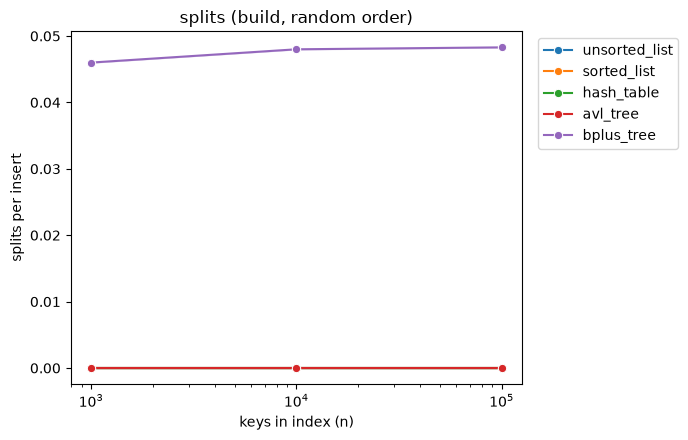

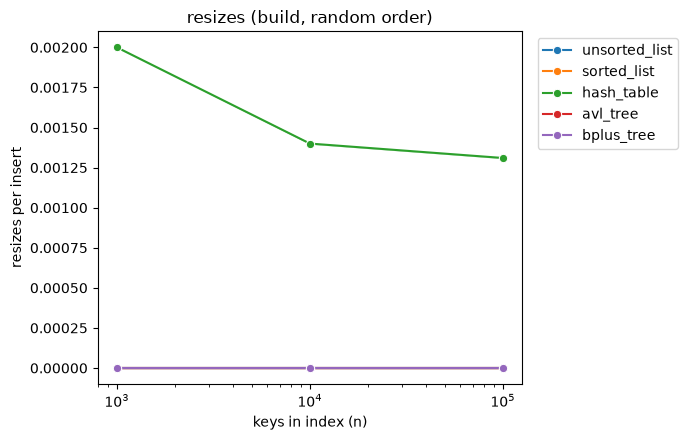

In [25]:
ORDER = "random"   # arrival order to look at; change to "sorted", "reversed" or "nearly_sorted"

# counter -> the operation where it matters
counter_ops = {
    "comparisons": "point_hit",
    "nodes_visited": "point_hit",
    "rotations": "build",
    "splits": "build",
    "resizes": "build",
}

for counter, op in counter_ops.items():
    col = f"{counter}_per_op"
    data = e5[(e5["operation"] == op) & (e5["insert_order"] == ORDER) & e5[counter].notna()]

    fig, ax = plt.subplots(figsize=(7, 4.5))
    sns.lineplot(data=data, x="n_keys", y=col, hue="index_type", marker="o", ax=ax)
    ax.set(xscale="log", xlabel="keys in index (n)",
           ylabel=f"{counter} per {'lookup' if op == 'point_hit' else 'insert'}",
           title=f"{counter} ({op}, {ORDER} order)")
    if counter == "comparisons":
        n = np.array(sorted(data["n_keys"].unique()))
        ax.plot(n, np.log2(n), "k--", label="log2(n)")   # what binary search should cost
        ax.set_yscale("log")
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

## Height of the tree based on insert order

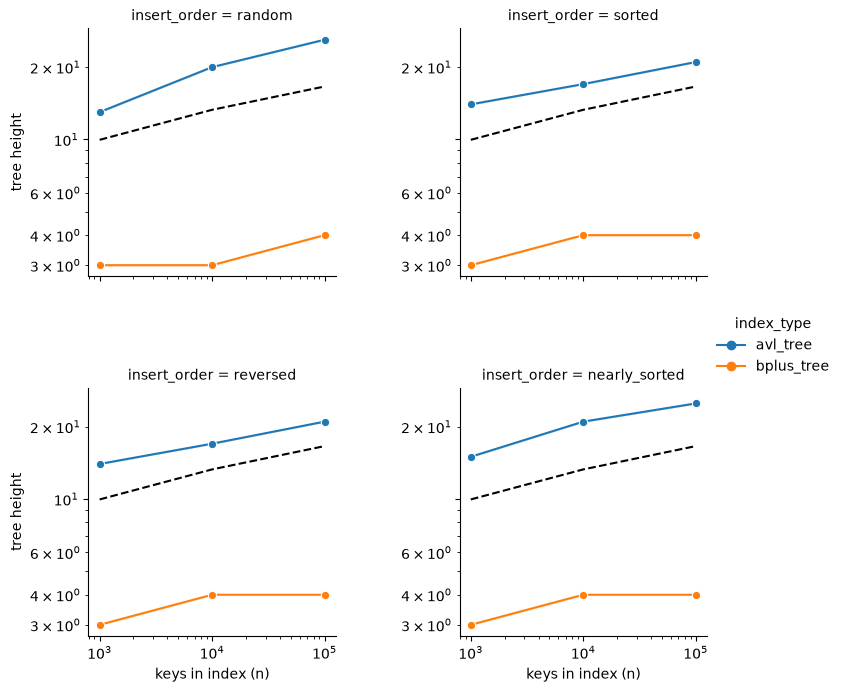

In [27]:
tall = e5[(e5["operation"] == "build") & e5["height"].notna()]   # only indexes that report a height

g = sns.relplot(data=tall, x="n_keys", y="height", hue="index_type",
                col="insert_order", col_wrap=2, kind="line", marker="o", height=3.5)
n = np.array(sorted(tall["n_keys"].unique()))
for ax in g.axes.flat:
    ax.plot(n, np.log2(n), "k--", label="log2(n)")   # height of a perfectly balanced binary tree
g.set(xscale="log", yscale="log")
g.set_axis_labels("keys in index (n)", "tree height")
g.figure.subplots_adjust(wspace=0.5, hspace=0.45)   # more space between the panels
plt.show()